# Freight-rate predication prject
## Objective:
Use Data from previous months to predict the posted rate in the last quarter of year 2026.

## Analysis

In [ ]:
# Libraries Importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


train_test_df = pd.read_csv('train-test.csv')
validation_df = pd.read_csv('validation.csv')

In [4]:
display(train_test_df.describe())
display(validation_df.describe())

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,0.926913,2.051334
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,0.074109,0.219804
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,1.098950,2.896350


In [5]:
# General Analysis
display(train_test_df.describe())

# show siszes of train-test and validation data
print("Train-Test Data Size:", train_test_df.shape)
print("Validation Data Size:", validation_df.shape)

# show number of null or missing values in train-test and validation data
print("Train-Test Data Null Values:\n", train_test_df.isnull().sum())
print("Validation Data Null Values:\n", validation_df.isnull().sum())

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


Train-Test Data Size: (48000, 14)
Validation Data Size: (12000, 13)
Train-Test Data Null Values:
 load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64
Validation Data Null Values:
 load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64


### 1. EDA Data Exploration
#### 1.1 Features exploration

In [6]:
# Logging all possible features to check, and what will
# bes useful for training and testing the model
feature_cols = train_test_df.columns[1:-1]
print("Feature Columns:", feature_cols.to_list())

display(train_test_df.head())

Feature Columns: ['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


#### 1.1.1 Pickup_Delivery analysis

In [7]:
# For train-test data
pick_train_test_df = set(train_test_df["pickup"].to_list())
delivery_train_test_df = set(train_test_df["delivery"].to_list())

all_unique_cities_train_test = pick_train_test_df.union(delivery_train_test_df)
possible_routes = len(pick_train_test_df) * len(delivery_train_test_df)
existing_routes = len(train_test_df)

print("Pickup Locations in Train-Test DataFrame:", len(pick_train_test_df))
print("Delivery Locations in Train-Test DataFrame:", len(delivery_train_test_df))
print("All Unique Cities:", len(all_unique_cities_train_test))
print("Possible Routes:", possible_routes)
print("Existing Routes:", existing_routes)

Pickup Locations in Train-Test DataFrame: 64
Delivery Locations in Train-Test DataFrame: 64
All Unique Cities: 64
Possible Routes: 4096
Existing Routes: 48000


In [8]:
# For validation data
pick_val_df = set(validation_df["pickup"].to_list())
delivery_val_df = set(validation_df["delivery"].to_list())

all_unique_cities_val = pick_val_df.union(delivery_val_df)
possible_routes = len(pick_val_df) * len(delivery_val_df)
existing_routes = len(validation_df)

print("Pickup Locations in Validation DataFrame:", len(pick_val_df))
print("Delivery Locations in Validation DataFrame:", len(delivery_val_df))
print("All Unique Cities:", len(all_unique_cities_val))
print("Possible Routes:", possible_routes)
print("Existing Routes:", existing_routes)

Pickup Locations in Validation DataFrame: 72
Delivery Locations in Validation DataFrame: 72
All Unique Cities: 72
Possible Routes: 5184
Existing Routes: 12000


In [9]:
# show different cities in train-test and validation data
diff_cities = all_unique_cities_val - all_unique_cities_train_test
print("Cities in Validation Data but not in Train-Test Data:", diff_cities)

Cities in Validation Data but not in Train-Test Data: {'Allentown', 'Knoxville', 'Jackson', 'Charlotte', 'San Diego', 'Laredo', 'Norfolk', 'Chicago'}


In [10]:
# build routes as "pickup-delivery"
routes_train_test = set(train_test_df['pickup'].astype(str) + '-' + train_test_df['delivery'].astype(str))
routes_val = set(validation_df['pickup'].astype(str) + '-' + validation_df['delivery'].astype(str))

# compare the two route sets
common_routes = routes_train_test & routes_val
only_train_test = routes_train_test - routes_val
only_val = routes_val - routes_train_test
union_routes = routes_train_test | routes_val

print("Common routes:", len(common_routes))
print("Only in train-test:", len(only_train_test))
print("Only in val:", len(only_val))
print("Union of routes:", len(union_routes))


Common routes: 3478
Only in train-test: 536
Only in val: 736
Union of routes: 4750


### 1.1.2 Longitude-Langtiude association with pickup and delivery

In [11]:
# Make sure each city has one longitude and latitude, and that they are consistent across both datasets
pickup_train_test = train_test_df[['pickup', 'pickup_lat', 'pickup_lon']].drop_duplicates()
delivery_train_test = train_test_df[['delivery', 'delivery_lat', 'delivery_lon']].drop_duplicates()

pickup_val = validation_df[['pickup', 'pickup_lat', 'pickup_lon']].drop_duplicates()
delivery_val = validation_df[['delivery', 'delivery_lat', 'delivery_lon']].drop_duplicates()


print("Unique Cities in Validation DataFrame:", delivery_val.shape[0])
print("Unique Cities in Train-Test DataFrame:", delivery_train_test.shape[0])
print("Unique Cities in Validation DataFrame:", pickup_val.shape[0])
print("Unique Cities in Train-Test DataFrame:", pickup_train_test.shape[0])

Unique Cities in Validation DataFrame: 72
Unique Cities in Train-Test DataFrame: 64
Unique Cities in Validation DataFrame: 72
Unique Cities in Train-Test DataFrame: 64


### 1.1.3 Does city value impact posted rate whatever the distance ?

In [12]:
# Build the route column (copy() avoids the SettingWithCopyWarning)
dist_train_test = train_test_df.copy()
dist_train_test['route'] = dist_train_test['pickup'].astype(str) + '-' + dist_train_test['delivery'].astype(str)

# Count rows per route, keep only routes that appear more than once
# (a route with a single row can't show any variation)
route_counts = dist_train_test['route'].value_counts()
repeated_routes = route_counts[route_counts > 1].index

# Pick one route at random. No random_state, so each run differs.
random_route_name = pd.Series(repeated_routes).sample(n=1).iloc[0]

# Keep ALL rows that belong to that route
route_df = dist_train_test[dist_train_test['route'] == random_route_name]

# Keep only route, distance , market_index, weight, posted_rate
route_df = route_df[['route', 'distance', 'market_index', 'weight', 'posted_rate']]
display(route_df)

,route,distance,market_index,weight,posted_rate
2568,Louisville-Jacksonville,511.7,0.95912,19830.0,1050.03
21160,Louisville-Jacksonville,490.4,1.34477,42157.0,1273.03
23354,Louisville-Jacksonville,467.7,1.34717,36474.0,1106.81
34082,Louisville-Jacksonville,493.0,0.91008,39021.0,1264.42


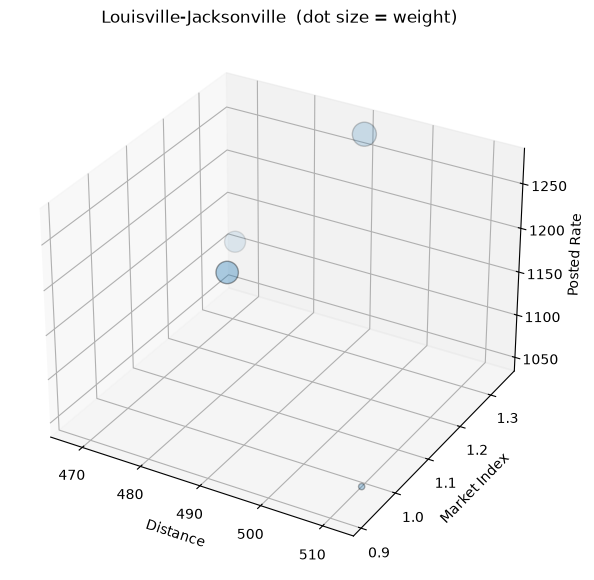

In [13]:

# Same route selection code as before, then:

# Drop rows missing any of the 4 columns used in the plot
# (dropna(subset=...): removes rows where those specific columns are NaN)
plot_df = route_df.dropna(subset=['distance', 'market_index', 'posted_rate', 'weight'])

# Turn weight into dot sizes: scale to 20-300 so small and large weights are both visible
# (a raw weight like 20000 would give giant dots)
w = plot_df['weight'].astype(float)
w_range = w.max() - w.min()
# if all weights are equal, w_range is 0, so fall back to a fixed size
sizes = 20 + 280 * (w - w.min()) / w_range if w_range > 0 else 100

# figure(): creates the canvas; add_subplot(projection='3d'): adds a 3D axes to it
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection='3d')

# scatter(x, y, z, s=sizes): one dot per row, s controls dot size
# alpha=0.6 makes dots semi-transparent so overlapping ones stay visible
ax.scatter(plot_df['distance'], plot_df['market_index'], plot_df['posted_rate'],
           s=sizes, alpha=0.6, edgecolor='k')

# Axis labels and title
ax.set_xlabel('Distance')
ax.set_ylabel('Market Index')
ax.set_zlabel('Posted Rate')
ax.set_title(f'{random_route_name}  (dot size = weight)')

plt.show()

### 1.1.4 Date Analysis

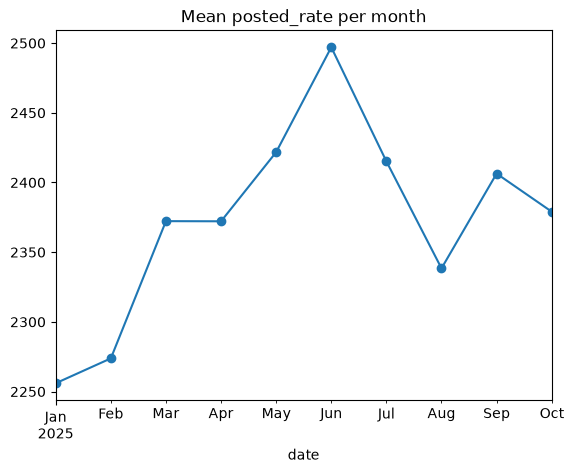

date
0    2349.308676
1    2372.890626
2    2405.086706
3    2403.265599
4    2376.849855
5    2373.714334
6    2335.073176
Name: posted_rate, dtype: float64
date
1     2255.967048
2     2273.804801
3     2372.268092
4     2372.162308
5     2421.776342
6     2497.030115
7     2415.162030
8     2338.407661
9     2406.374013
10    2379.051374
Name: posted_rate, dtype: float64


In [14]:
df = train_test_df.copy()

# to_datetime(): converts the text column to real dates so pandas can group by month, weekday, etc.
df['date'] = pd.to_datetime(df['date'])

# Mean posted_rate per month: a trend or seasonal pattern shows up as a moving line
# dt.to_period('M'): rounds each date to its month; groupby + mean: average rate per month
monthly = df.groupby(df['date'].dt.to_period('M'))['posted_rate'].mean()
monthly.plot(marker='o', title='Mean posted_rate per month')
plt.show()

# Same idea per weekday (0 = Monday) and per month number (1-12, shows seasonality across years)
print(df.groupby(df['date'].dt.dayofweek)['posted_rate'].mean())
print(df.groupby(df['date'].dt.month)['posted_rate'].mean())

### 2.0 Visual Analysis
#### 2.1. Plotting all distributions for each features

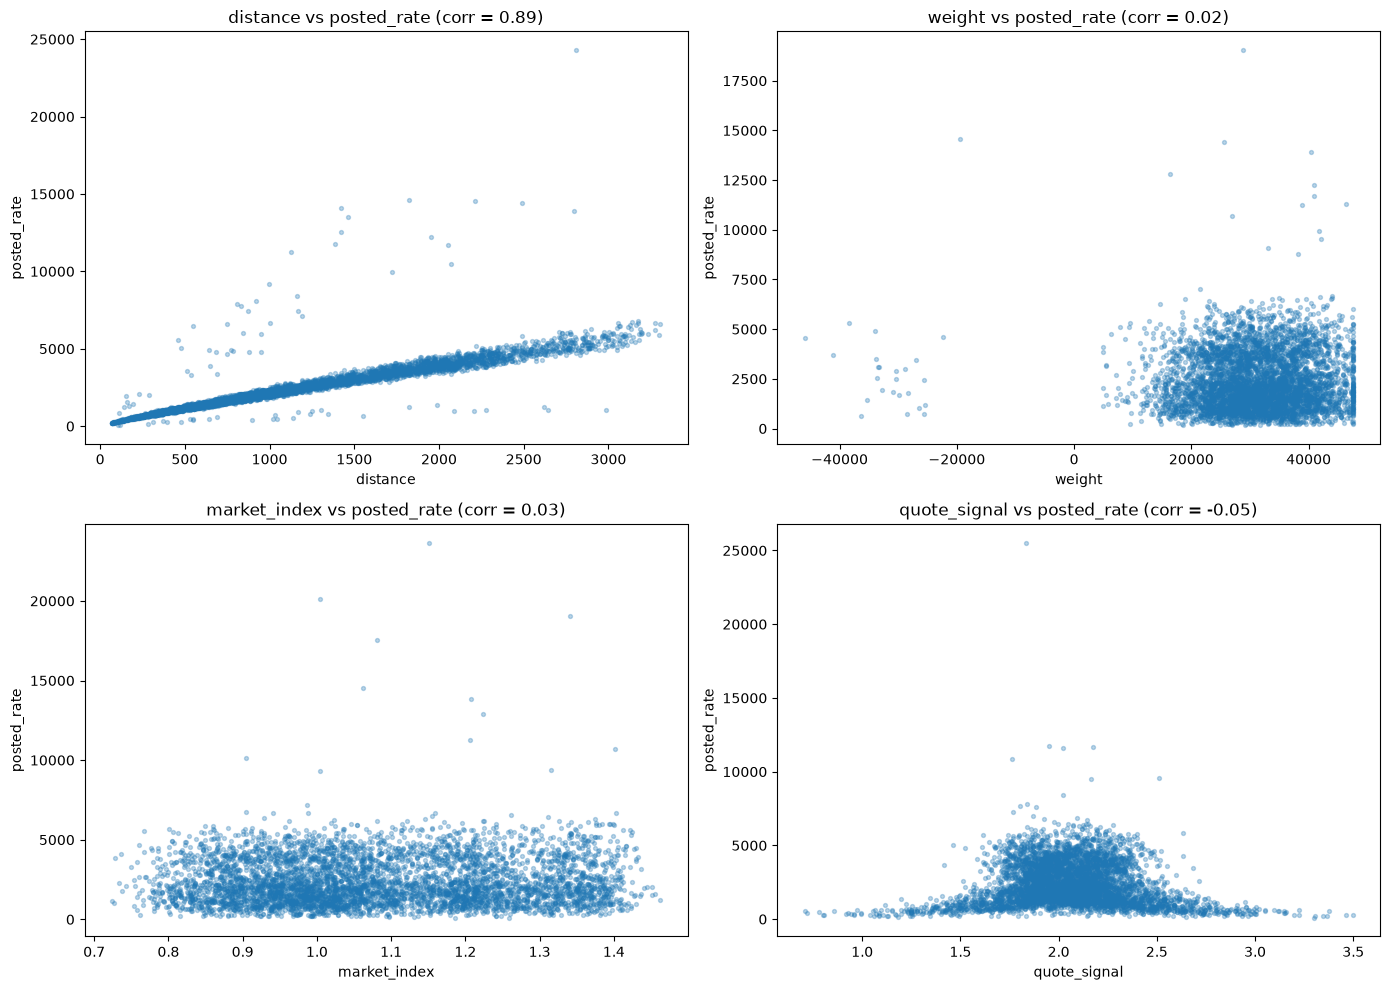

In [15]:
features = ['distance', 'weight', 'market_index', 'quote_signal']

# subplots(rows, cols): creates a grid of plots; returns the figure and an array of axes
# figsize=(14, 10): size of the whole canvas in inches
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# axes is a 2x2 array; flatten() turns it into a 1D list of 4 axes so we can loop over it
axes = axes.flatten()

# zip pairs each feature name with one axis: (distance, ax0), (weight, ax1), ...
for feature, ax in zip(features, axes):
    # Keep only rows where both the feature and posted_rate exist
    # (dropna(subset=...): removes rows with NaN in those columns)
    data = train_test_df[[feature, 'posted_rate']].dropna()

    # If there are many rows, plot a random 5000 so the plot stays fast and readable
    # (sample(n): random rows; min() avoids asking for more rows than exist)
    data = data.sample(n=min(5000, len(data)))

    # scatter(x, y): one dot per row
    # s=8: small dots, alpha=0.3: semi-transparent so dense areas look darker
    ax.scatter(data[feature], data['posted_rate'], s=8, alpha=0.3)

    # Label the axes and add a title with the Pearson correlation for this feature
    # (corr(): correlation between two columns, from -1 to 1)
    ax.set_xlabel(feature)
    ax.set_ylabel('posted_rate')
    ax.set_title(f"{feature} vs posted_rate (corr = {data[feature].corr(data['posted_rate']):.2f})")

# tight_layout(): adjusts spacing so titles and labels don't overlap
plt.tight_layout()
plt.show()

In [16]:
# confirm the cap
print(train_test_df['weight'].value_counts().head())

cap = train_test_df['weight'].max()   # the suspected cap value
n_capped = (train_test_df['weight'] == cap).sum()   # rows sitting exactly at the cap
print(cap, n_capped, f"{n_capped / len(train_test_df):.1%} of rows")

weight
 47500.0    1191
 5000.0       31
-47500.0      13
 32436.0      10
 32153.0      10
Name: count, dtype: int64
47500.0 1191 2.5% of rows


In [17]:
# confirm the cap
print(validation_df['weight'].value_counts().head())

cap = validation_df['weight'].max()   # the suspected cap value
n_capped = (validation_df['weight'] == cap).sum()   # rows sitting exactly at the cap
print(cap, n_capped, f"{n_capped / len(validation_df):.1%} of rows")

weight
47500.0    297
5000.0       7
27854.0      5
36431.0      5
40841.0      4
Name: count, dtype: int64
47500.0 297 2.5% of rows


#### 2.2 Box Plots

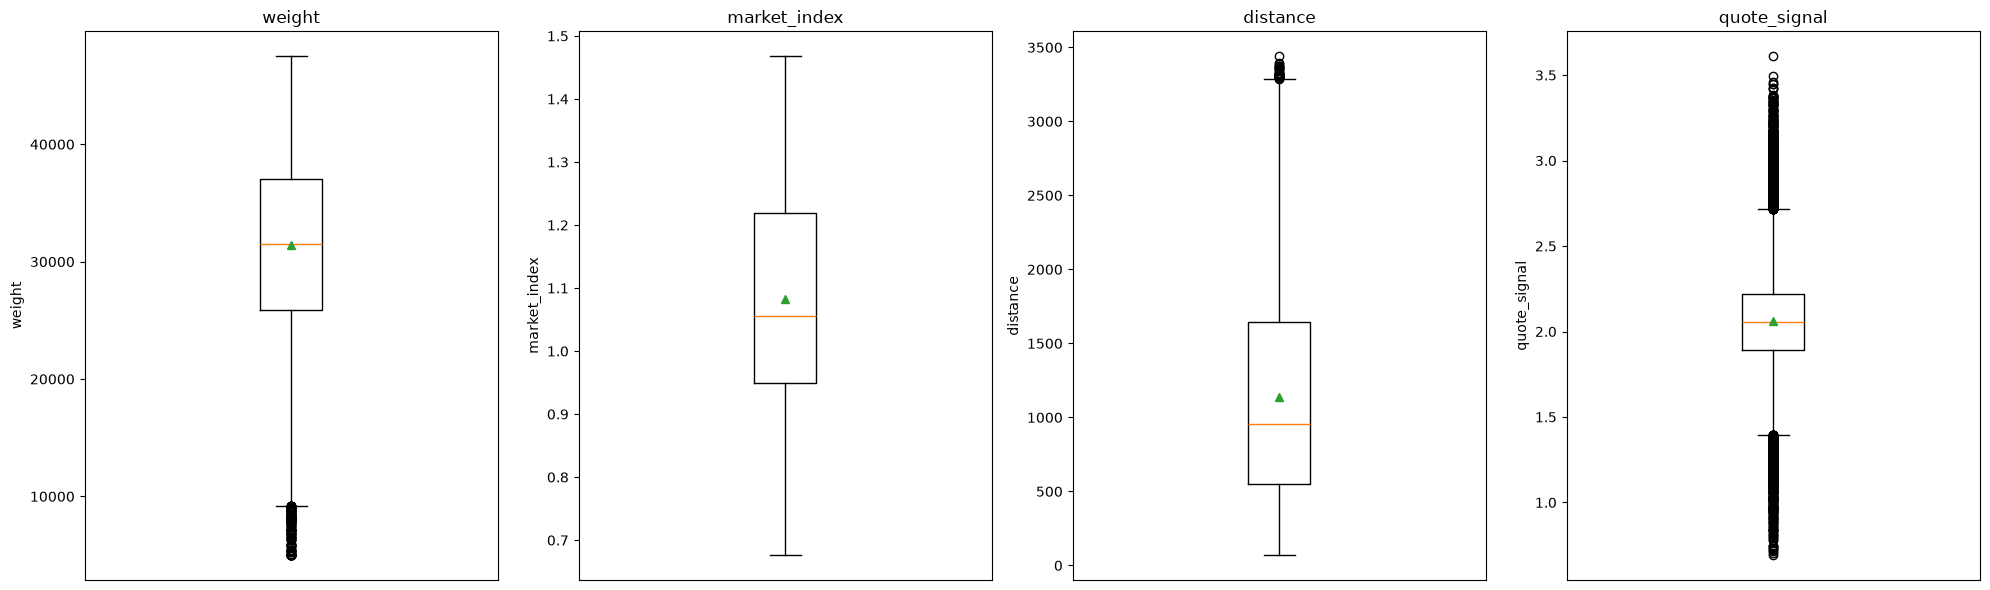

In [18]:
features = ['weight', 'market_index', 'distance', 'quote_signal']

# copy(): plot_df is a separate dataframe, so train_test_df keeps its original values
plot_df = train_test_df.copy()

# abs(): turns -47500 into 47500 (NaN stays NaN)
plot_df['weight'] = plot_df['weight'].abs()

fig, axes = plt.subplots(1, len(features), figsize=(5 * len(features), 6), squeeze=False)
axes = axes[0]

for feature, ax in zip(features, axes):
    # Same box plot as before, now reading from plot_df
    ax.boxplot(plot_df[feature].dropna(), showmeans=True)
    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

## Data cleaning

In [ ]:
train_test